
 Logistic Regression
Accuracy: 0.483
Precision: 0.483
Recall: 0.483
F1-score: 0.482

 SVM
Accuracy: 0.667
Precision: 0.8
Recall: 0.667
F1-score: 0.625

 Naive Bayes
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

MODEL COMPARISON
              Model  Accuracy  Precision   Recall  F1-score
Logistic Regression  0.483333   0.483165 0.483333  0.482038
                SVM  0.666667   0.800000 0.666667  0.625000
        Naive Bayes  1.000000   1.000000 1.000000  1.000000

Best model based on F1-score: Naive Bayes


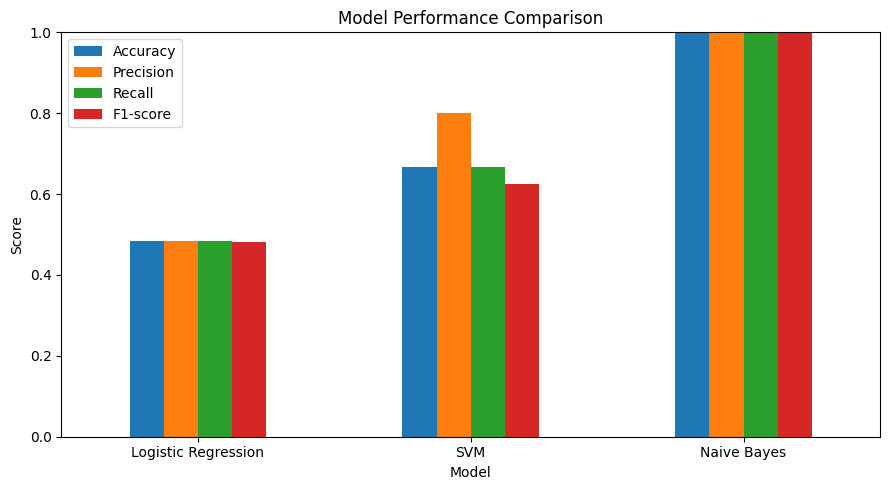

In [11]:
# Logistic Regression, SVM, and Naive Bayes

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs, make_circles
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

data_type = "circles"

if data_type == "blobs":
    X, y = make_blobs(n_samples=200, centers=2, cluster_std=1.0, random_state=42)
elif data_type == "circles":
    X, y = make_circles(n_samples=200, factor=0.5, noise=0.1, random_state=42)
elif data_type == "csv":
    df = pd.read_csv("ml_lab_practice_2.csv")
    target = "target"
    df = df.dropna(subset=[target])
    X = pd.get_dummies(df.drop(columns=[target]), drop_first=True)
    y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

models = {
    "Logistic Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),
    "SVM": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        SVC(kernel="poly")
    ),
    "Naive Bayes": make_pipeline(
        SimpleImputer(strategy="median"),
        GaussianNB()
    )
}
# kernel = linear, poly, sigmoid or rbf
selected = ["Logistic Regression", "SVM", "Naive Bayes"]

results = []

for name in selected:
    model = models[name]
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    pre = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)
    results.append([name, acc, pre, rec, f1])
    print("\n", name)
    print("Accuracy:", round(acc, 3))
    print("Precision:", round(pre, 3))
    print("Recall:", round(rec, 3))
    print("F1-score:", round(f1, 3))

results_df = pd.DataFrame(
    results,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1-score"]
)

print("\nMODEL COMPARISON")
print(results_df.to_string(index=False))

best = results_df.loc[results_df["F1-score"].idxmax(), "Model"]
print("\nBest model based on F1-score:", best)

results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", ylim=(0, 1), figsize=(9, 5)
)
plt.ylabel("Score")
plt.title("Model Performance Comparison")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
